#Phase 1: Algorithms

In [ ]:
!pip install deap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.0/136.0 kB 9.3 MB/s eta 0:00:00


In [ ]:
!pip install pyswarm

  Preparing metadata (setup.py) ... done
  Created wheel for pyswarm: filename=pyswarm-0.6-py3-none-any.whl size=4463 sha256=9bdc20b9156b4da096112425a32aa75e9e684035bb0f45b0476823efa95f4ed6
  Stored in directory: /root/.cache/pip/wheels/93/15/89/3970ef96abd6123028010a90f007c4e6a2bed700db0aa2d36a
Successfully built pyswarm


In [ ]:
from deap import base, creator, tools, algorithms
from scipy.optimize import differential_evolution
from pyswarm import pso
from scipy.optimize import dual_annealing

In [ ]:
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#get helper functions
%run '/content/drive/MyDrive/Colab Notebooks/RCC_Beam_Optimization/helper_functions.ipynb'


In [ ]:
param_ranges

{'b': (200.0, 500.0), 'd': (300.0, 1500.0), 'Ast': (200.0, 10000.0)}

In [ ]:
# ================================
# Phase 1: Optimizers
# ================================

def clip_design(b, d, Ast, param_ranges):
    b = max(min(b, param_ranges['b'][1]), param_ranges['b'][0])
    d = max(min(d, param_ranges['d'][1]), param_ranges['d'][0])
    Ast = max(min(Ast, param_ranges['Ast'][1]), param_ranges['Ast'][0])
    # if b / d < 0.3:
    #     b = 0.3001 * d
    #     # Re-clip b in case it exceeds max after adjustment
    #     b = max(min(b, param_ranges['b'][1]), param_ranges['b'][0])
    return b, d, Ast

def run_ga(fck, fy, Mu, param_ranges, generations=50, population_size=100):
    if "FitnessMax" not in creator.__dict__:
        creator.create("FitnessMax", base.Fitness, weights=(1.0,))
    if "Individual" not in creator.__dict__:
        creator.create("Individual", list, fitness=creator.FitnessMax)

    toolbox = base.Toolbox()
    toolbox.register("attr_b", np.random.randint, *param_ranges['b'])
    toolbox.register("attr_d", np.random.randint, *param_ranges['d'])
    toolbox.register("attr_Ast", np.random.randint, *param_ranges['Ast'])
    toolbox.register("individual", tools.initCycle, creator.Individual,
                     (toolbox.attr_b, toolbox.attr_d, toolbox.attr_Ast), n=1)
    toolbox.register("population", tools.initRepeat, list, toolbox.individual)

    def evaluate(ind):
        b, d, Ast = ind
        return get_reward(b, d, Ast, fck, fy, Mu),

    toolbox.register("evaluate", evaluate)
    toolbox.register("mate", tools.cxBlend, alpha=0.5)
    toolbox.register("mutate", tools.mutGaussian, mu=0, sigma=50, indpb=0.2)
    toolbox.register("select", tools.selTournament, tournsize=3)

    def feasibility(ind):
        return (1,) if is_valid_design(*ind, fck, fy, Mu) else (0,)

    toolbox.decorate("evaluate", tools.DeltaPenalty(feasibility, 0.0))

    pop = toolbox.population(n=population_size)
    hof = tools.HallOfFame(1)
    algorithms.eaSimple(pop, toolbox, cxpb=0.7, mutpb=0.2, ngen=generations,
                        halloffame=hof, verbose=False)

    return clip_design(*hof[0], param_ranges)

def run_de(fck, fy, Mu, param_ranges, max_iter=100, pop_size=15):
    def objective(x):
        b, d, Ast = x
        if not is_valid_design(b, d, Ast, fck, fy, Mu): return 1e6
        return -get_reward(b, d, Ast, fck, fy, Mu)

    bounds = [param_ranges['b'], param_ranges['d'], param_ranges['Ast']]

    result = differential_evolution(objective, bounds, maxiter=max_iter, popsize=pop_size)
    return clip_design(*result.x, param_ranges)

def run_pso(fck, fy, Mu, param_ranges, swarmsize=30, maxiter=100):
    from pyswarm import pso

    def objective(x):
        b, d, Ast = x
        if not is_valid_design(b, d, Ast, fck, fy, Mu): return 1e6
        return -get_reward(b, d, Ast, fck, fy, Mu)

    lb = [param_ranges[k][0] for k in ['b', 'd', 'Ast']]
    ub = [param_ranges[k][1] for k in ['b', 'd', 'Ast']]

    xopt, _ = pso(objective, lb, ub, swarmsize=swarmsize, maxiter=maxiter)
    return clip_design(*xopt, param_ranges)

def run_sa(fck, fy, Mu, param_ranges, max_iter=1000):
    from scipy.optimize import dual_annealing

    def objective(x):
        b, d, Ast = x
        if not is_valid_design(b, d, Ast, fck, fy, Mu): return 1e6
        return -get_reward(b, d, Ast, fck, fy, Mu)

    bounds = [param_ranges[k] for k in ['b', 'd', 'Ast']]
    result = dual_annealing(objective, bounds, maxiter=max_iter)
    return clip_design(*result.x, param_ranges)

#Phase 2: Dataset builder

In [ ]:
# ================================
# Phase 2: Dataset Collector
# ================================

def collect_best_by_ensemble(algorithms, fck_list, fy_list, Mu_list, param_ranges, filename):
    import itertools, pandas as pd

    rows = []

    for fck, fy, Mu in itertools.product(fck_list, fy_list, Mu_list):
        best_reward = -1e9
        best_row = None

        for algo in algorithms:
            try:
                if algo == "GA":
                    b, d, Ast = run_ga(fck, fy, Mu, param_ranges)
                elif algo == "DE":
                    b, d, Ast = run_de(fck, fy, Mu, param_ranges)
                elif algo == "PSO":
                    b, d, Ast = run_pso(fck, fy, Mu, param_ranges)
                elif algo == "SA":
                    b, d, Ast = run_sa(fck, fy, Mu, param_ranges)
                else:
                    continue

                reward = get_reward(b, d, Ast, fck, fy, Mu)
                if is_valid_design(b, d, Ast, fck, fy, Mu) and reward > best_reward:
                    best_reward = reward
                    b=math.ceil(b)
                    d=math.ceil(d)
                    Ast=math.ceil(Ast*10)/10
                    if b < 0.3*d:
                        b = math.ceil(0.3*d)
                    best_row = {
                        "fck": fck,
                        "fy": fy,
                        "Mu": Mu,
                        "b": b,
                        "d": d,
                        "Ast": Ast,
                        "algorithm": algo,

                    }

            except Exception as e:
                print(f"{algo} failed for fck={fck}, fy={fy}, Mu={Mu}: {e}")

        if best_row:
            rows.append(best_row)

    df = pd.DataFrame(rows)
    df["is_valid"] = df.apply(lambda row: is_valid_design(row.b, row.d, row.Ast, row.fck, row.fy, row.Mu), axis=1)
    df["cost"] = df.apply(lambda row: get_cost(row.b, row.d, row.Ast), axis=1)
    df["MOR"] = df.apply(lambda row: calculate_moment_capacity(row.b, row.d, row.Ast, row.fck, row.fy)[0], axis=1).round(4)
    df["Mul"] = df.apply(lambda row: calculate_moment_capacity(row.b, row.d, row.Ast, row.fck, row.fy)[1], axis=1).round(4)
    df["utilization"] = (df["Mu"] / df["MOR"]).round(4)
    df["rho"] = (df["Ast"] / (df["b"] * df["d"])).round(4)
    df["bd_ratio"] = (df["b"] / df["d"]).round(3)

    df.to_csv(filename, index=False)
    print(f"Saved {len(df)} records to {filename}")


In [ ]:
fck_list = list(range(20, 51, 5))
fy_list=[415, 500, 550]
Mu_list = list(range(40, 1001, 20))

In [ ]:
len(fck_list) * len(fy_list) * len(Mu_list)

1029

In [ ]:
collect_best_by_ensemble(
    algorithms=["GA", "DE", "PSO", "SA"],
    fck_list=fck_list,
    fy_list=fy_list,
    Mu_list=Mu_list,

    param_ranges=param_ranges,
    filename="ensemble_best_designs.csv"
)


Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100


/tmp/ipython-input-33-3713639065.py:68: RuntimeWarning: invalid value encountered in log
  cost_score = np.log(cost_max / cost) / np.log(cost_max / cost_min)


Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping search: maximum iterations reached --> 100
Stopping sea

#Exploratory data analysis (EDA)

In [ ]:
# Load dataset
df = pd.read_csv("ensemble_best_designs_1029.csv")
df.sample(10, ignore_index=True)

,fck,fy,Mu,b,d,Ast,algorithm,is_valid,cost,MOR,Mul,utilization,rho,bd_ratio
0,25,550,140,201,473,752.8,DE,True,2253.42,140.543,146.371,0.9961,0.0079,0.425
1,35,500,1000,273,907,3096.6,SA,True,7117.33,1002.312,1045.642,0.9977,0.0125,0.301
2,25,500,40,201,300,346.8,PSO,True,1285.63,40.024,60.161,0.9994,0.0058,0.670
3,25,415,520,241,801,2230.0,DE,True,5346.38,520.588,533.859,0.9989,0.0116,0.301
4,50,500,680,220,732,2541.8,GA,True,5209.04,680.932,784.058,0.9986,0.0158,0.301
5,45,500,60,200,300,507.8,PSO,True,1458.07,60.003,107.752,1.0000,0.0085,0.667
6,25,550,520,244,811,1644.1,SA,True,4775.13,520.774,522.357,0.9985,0.0083,0.301
7,50,500,240,201,569,1071.5,SA,True,2893.11,240.233,432.839,0.9990,0.0094,0.353
8,45,415,920,249,830,3680.5,PSO,True,7144.92,920.834,1066.030,0.9991,0.0178,0.300
9,20,500,820,303,1010,2304.2,GA,True,7122.77,820.776,822.342,0.9991,0.0075,0.300


In [ ]:
df.describe()

,fck,fy,Mu,b,d,Ast,cost,MOR,Mul,utilization,rho,bd_ratio
count,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000
mean,35.000000,488.333333,520.000000,230.263362,712.199223,1935.786686,4662.110991,520.911005,575.220574,0.998009,0.011384,0.342060
std,10.004863,55.754610,282.980248,32.047230,180.765520,838.420659,1771.224203,283.328806,291.287090,0.001462,0.002945,0.091167
min,20.000000,415.000000,40.000000,200.000000,300.000000,294.700000,1223.880000,40.000000,46.870000,0.986000,0.004900,0.300000
25%,25.000000,415.000000,280.000000,201.000000,624.000000,1215.500000,3232.970000,280.428000,343.001000,0.997500,0.009400,0.301000
50%,35.000000,500.000000,520.000000,221.000000,734.000000,1965.700000,4726.750000,520.890000,567.013000,0.998300,0.011100,0.301000
75%,45.000000,550.000000,760.000000,253.000000,839.000000,2592.600000,6118.930000,761.526000,813.481000,0.998900,0.013900,0.322000
max,50.000000,550.000000,1000.000000,326.000000,1086.000000,3747.400000,8689.400000,1002.574000,1390.411000,1.000000,0.018000,0.670000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1029 entries, 0 to 1028
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   fck          1029 non-null   int64  
 1   fy           1029 non-null   int64  
 2   Mu           1029 non-null   int64  
 3   b            1029 non-null   int64  
 4   d            1029 non-null   int64  
 5   Ast          1029 non-null   float64
 6   algorithm    1029 non-null   object 
 7   is_valid     1029 non-null   bool   
 8   cost         1029 non-null   float64
 9   MOR          1029 non-null   float64
 10  Mul          1029 non-null   float64
 11  utilization  1029 non-null   float64
 12  rho          1029 non-null   float64
 13  bd_ratio     1029 non-null   float64
dtypes: bool(1), float64(7), int64(5), object(1)
memory usage: 105.6+ KB


In [ ]:
duplicates = df.duplicated().sum()
print(duplicates)

0


In [ ]:
print("🧹 Missing Values:")
print(df.isnull().sum())

🧹 Missing Values:
fck            0
fy             0
Mu             0
b              0
d              0
Ast            0
algorithm      0
is_valid       0
cost           0
MOR            0
Mul            0
utilization    0
rho            0
bd_ratio       0
dtype: int64


All high-readability histograms have been saved successfully!


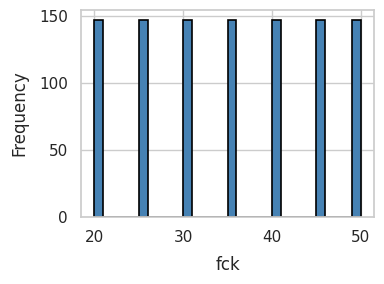

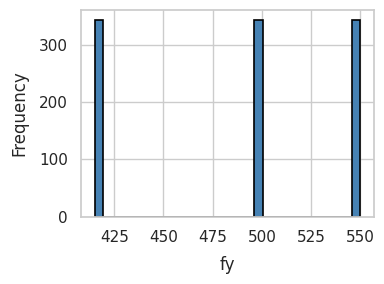

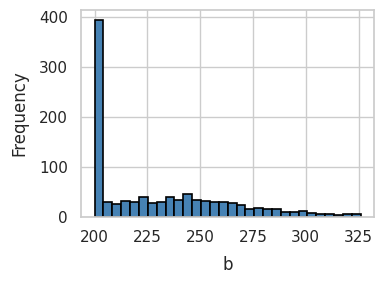

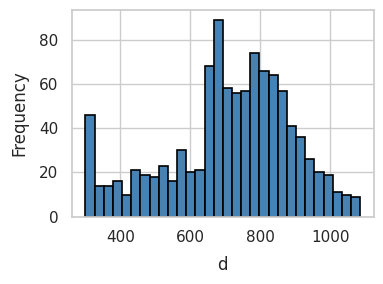

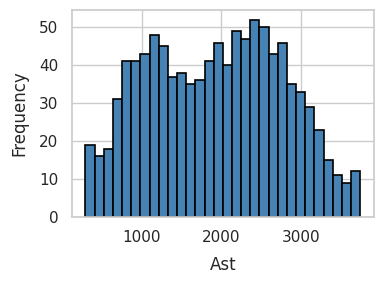

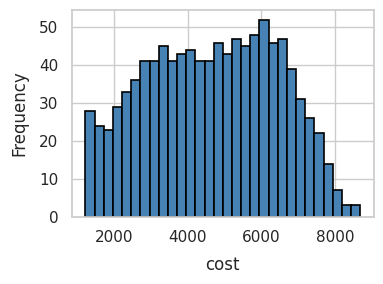

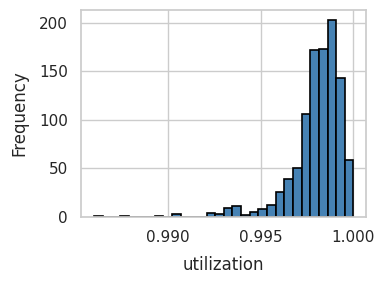

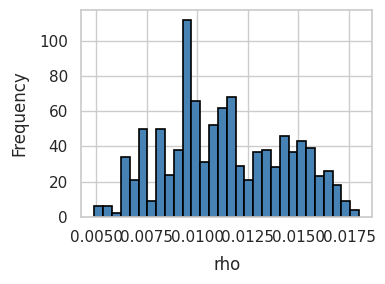

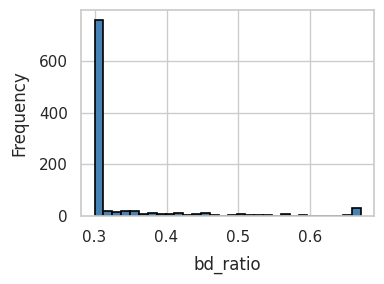

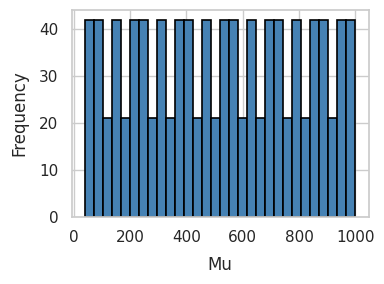

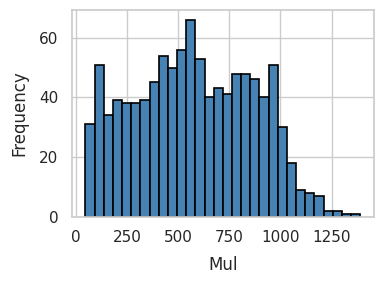

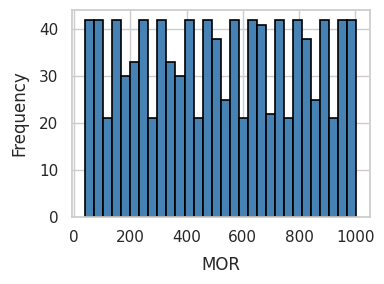

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Apply a high-readability style context for small/talk-sized figures
# This automatically scales up fonts, line widths, and marker sizes
sns.set_context("talk", rc={"font.size": 14})
sns.set_theme(style="whitegrid") # Keeps layout clean

numeric_cols = ['fck', 'fy', 'b', 'd', 'Ast', 'cost', 'utilization', 'rho', 'bd_ratio', 'Mu', 'Mul', 'MOR']

for col in numeric_cols:
    # 2. Keep the small physical dimensions but ensure clear proportions
    plt.figure(figsize=(4, 3))

    # 3. Thicker edge lines make bars pop even when shrunk on a page
    df[col].hist(bins=30, color="steelblue", edgecolor="black", linewidth=1.2)

    # 4. Bold titles and padded labels prevent overlapping text
    # plt.title(f"Histogram of {col}", weight="bold", pad=12)
    plt.xlabel(col, labelpad=8)
    plt.ylabel("Frequency", labelpad=8)

    # 5. Clean layout adjustments
    plt.tight_layout()

    # 6. Save with bbox_inches='tight' to ensure no labels are cropped out
    plt.savefig(f"{col}_histogram.png", dpi=300, bbox_inches="tight")
    # plt.close()

print("All high-readability histograms have been saved successfully!")

In [ ]:
df1 = df.drop(columns=['algorithm', 'is_valid', 'MOR', 'Mul', 'bd_ratio'], inplace=False)

In [ ]:
df1.describe()

,fck,fy,Mu,b,d,Ast,cost,utilization,rho
count,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000
mean,35.000000,488.333333,520.000000,230.263362,712.199223,1935.786686,4662.110991,0.998009,0.011384
std,10.004863,55.754610,282.980248,32.047230,180.765520,838.420659,1771.224203,0.001462,0.002945
min,20.000000,415.000000,40.000000,200.000000,300.000000,294.700000,1223.880000,0.986000,0.004900
25%,25.000000,415.000000,280.000000,201.000000,624.000000,1215.500000,3232.970000,0.997500,0.009400
50%,35.000000,500.000000,520.000000,221.000000,734.000000,1965.700000,4726.750000,0.998300,0.011100
75%,45.000000,550.000000,760.000000,253.000000,839.000000,2592.600000,6118.930000,0.998900,0.013900
max,50.000000,550.000000,1000.000000,326.000000,1086.000000,3747.400000,8689.400000,1.000000,0.018000


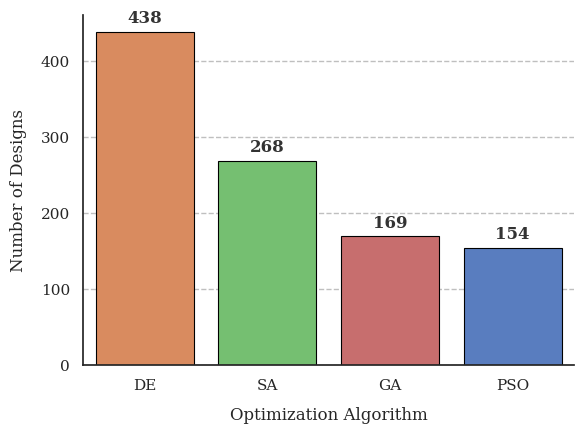

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Establish publication-level global styling
sns.set_theme(style="white")  # Clean white background without heavy gridlines
plt.rcParams.update(
    {
        "font.family": "serif",  # Matches standard journal body text (e.g., Times New Roman)
        "font.size": 12,  # Readability baseline
    }
)

# 2. Initialize figure size tailored for a single-column or half-page print
fig, ax = plt.subplots(figsize=(6, 4.5))

# 3. Create the count plot with a professional palette
sns.countplot(
    data=df,
    x="algorithm",
    hue="algorithm",
    order=df["algorithm"].value_counts().index,
    palette="muted",  # More distinct and professional than pastel
    legend=False,
    ax=ax,
    edgecolor="black",  # Crisp boundaries for the bars
    linewidth=0.8,
)

# 4. Refined count annotations (larger font and a slight vertical offset)
for p in ax.patches:
    height = p.get_height()
    if height > 0:  # Skip empty patches if any
        ax.annotate(
            f"{int(height)}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            xytext=(0, 4),  # 4pt offset above the bar
            textcoords="offset points",
            fontweight="bold",
            color="#333333",
        )

# 5. Clean layout & typography rules
# plt.title("Distribution of Optimization Designs by Algorithm", pad=15)
plt.xlabel("Optimization Algorithm", labelpad=10)
plt.ylabel("Number of Designs", labelpad=10)

# 6. Add clean, subtle background horizontal gridlines manually
ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle="--", alpha=0.5, color="gray")

# 7. Despine to remove top and right borders
sns.despine(ax=ax, top=True, right=True, left=False, bottom=False)

# 8. Save with a clean bounding box
plt.tight_layout()
plt.savefig("algorithms.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
import os
import zipfile
from google.colab import files

# 1. Define the zip archive name
zip_filename = "optimized_beam_plots.zip"

# 2. Create the zip archive and write all .png files into it
with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for file in os.listdir('.'):
        if file.endswith('.png'):
            zipf.write(file)
            print(f"Added to archive: {file}")

# 3. Trigger the automatic download in your browser
print(f"\nDownloading {zip_filename}...")
files.download(zip_filename)

Added to archive: cost_histogram.png
Added to archive: fy_histogram.png
Added to archive: Ast_histogram.png
Added to archive: rho_histogram.png
Added to archive: utilization_histogram.png
Added to archive: Mu_histogram.png
Added to archive: algorithms.png
Added to archive: bd_ratio_histogram.png
Added to archive: b_histogram.png
Added to archive: correlation_matrix.png
Added to archive: MOR_histogram.png
Added to archive: d_histogram.png
Added to archive: fck_histogram.png
Added to archive: Mul_histogram.png



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#Comparison with Prakash et al

In [ ]:
prakash = pd.read_excel("verification.xlsx", sheet_name = "Prakash_2")
prakash = prakash.drop(columns = ["ρ", "bd^2"])
prakash['cost'] = get_cost(prakash['b'], prakash['d'], prakash['Ast'])
prakash

,fck,fy,Mu,b,d,Ast,cost
0,20,415,200,200.303949,600.911848,1149.703432,3069.00
1,20,415,440,260.513603,781.540809,1944.767172,5191.33
2,25,415,660,276.837013,830.511038,2745.143965,6465.66
3,25,415,800,295.170423,885.511270,3120.775249,7350.38
4,25,415,300,212.854708,638.564124,1622.868528,3822.35
5,20,500,580,289.219533,867.658598,1894.123909,5845.80
6,25,500,720,288.553126,865.659377,2356.756565,6336.91
7,30,500,500,240.460938,721.382814,1963.963804,4760.36
8,25,500,1000,321.944950,965.834851,2933.772238,7888.40
9,30,500,900,292.506400,877.519199,2906.130749,7044.04


In [ ]:
mha = pd.read_csv("ensemble_best_designs_1029.csv")
columns = ["fck", "fy", "Mu", "b", "d", "Ast", "cost"]
mha = mha[columns]
mha

,fck,fy,Mu,b,d,Ast,cost
0,20,415,40,200,301,434.8,1380.85
1,20,415,60,201,347,584.4,1688.46
2,20,415,80,201,387,709.0,1946.00
3,20,415,100,200,442,764.9,2166.63
4,20,415,120,201,477,858.5,2381.65
...,...,...,...,...,...,...,...
1024,50,550,920,236,784,2989.7,6061.04
1025,50,550,940,239,794,3000.8,6144.37
1026,50,550,960,245,816,2940.8,6230.74
1027,50,550,980,243,809,3059.6,6311.31


In [ ]:
df_keys = prakash[["fck", "fy", "Mu"]].copy()
df_keys["_order"] = df_keys.index

mha_selected = mha.merge(df_keys, on=["fck", "fy", "Mu"], how="inner")
mha_selected = mha_selected.sort_values("_order").drop(columns="_order")
mha_selected

,fck,fy,Mu,b,d,Ast,cost
0,20,415,200,201,618,1102.3,3074.70
1,20,415,440,244,813,1865.6,5025.87
4,25,415,660,259,863,2641.9,6256.20
5,25,415,800,276,918,3016.1,7115.21
3,25,415,300,200,666,1550.0,3701.45
2,20,500,580,270,900,1829.2,5655.29
6,25,500,720,271,897,2281.1,6153.23
8,30,500,500,225,750,1886.4,4604.40
7,25,500,1000,302,1004,2822.6,7650.16
9,30,500,900,275,914,2783.3,6829.10
